# Lesson 1 — Data: from raw text to batches

⏱ **Duration:** ~25 min &nbsp;|&nbsp; 📚 **Builds on:** Lesson 0 &nbsp;|&nbsp; 💻 **Runs on:** a laptop CPU

**By the end of this lesson you will be able to:**

- load and clean a text corpus
- explain why we split train/validation and why the split is interleaved
- describe what an `(x, y)` training batch is and why `y` is `x` shifted by one

> 🎤 *Teaching tip:* run the cells in order; every code cell is short enough to be explained live.

## 1. The training text

The model only knows what it reads. We use two public texts:

* **King James Bible** (Project Gutenberg) — archaic English, very repetitive structure
* **Mastering Bitcoin, 3rd ed.** (open source) — modern technical English

Two very different styles in one corpus is a nice teaching tool: you will see the model pick up *both*.

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # lets us `import myllm` without installing it

import torch
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(4)
DATA = ROOT / "data" / "raw"       # training text lives here
MODELS = ROOT / "models"           # checkpoints are written here

In [2]:
from myllm.data import load_corpus, strip_gutenberg, clean_text
for f in sorted(DATA.glob("*.txt")):
    raw = f.read_text(encoding="utf-8", errors="ignore")
    print(f"{f.name}: {len(raw):,} characters, {len(raw.split()):,} whitespace-separated words")
    print("   starts with:", repr(raw[:110]))

bible_kjv_full.txt: 4,330,232 characters, 821,122 whitespace-separated words
   starts with: '\nThe First Book of Moses: Called Genesis\n\n1:1 In the beginning God created the heaven and the earth.\n\n1:2 And '
mastering_bitcoin_third_edition.txt: 900,737 characters, 136,195 whitespace-separated words
   starts with: 'MASTERING BITCOIN: PROGRAMMING THE OPEN BLOCKCHAIN\nThird Edition, first print (source archive: third_edition_p'


## 2. Cleaning

Real files contain junk the model should not learn: license headers, URLs, e-mail addresses.
`strip_gutenberg` removes the Project Gutenberg boilerplate and `clean_text` removes URLs and e-mails.
Here is what they do on a small example:

In [3]:
dirty = """The Project Gutenberg eBook, license text nobody wants to learn...
*** START OF THE PROJECT GUTENBERG EBOOK THE BIBLE ***
In the beginning God created the heaven and the earth.   See https://example.org or mail me@example.org
*** END OF THE PROJECT GUTENBERG EBOOK THE BIBLE ***
More license text..."""
print(clean_text(strip_gutenberg(dirty)))

In the beginning God created the heaven and the earth. See or mail


> 🔎 **Always look at your data.** The files in `data/raw` were already stripped by the download script, but the converted
> *Mastering Bitcoin* text still contains leftovers of its source format. Let's find them.

In [4]:
book = (DATA / "mastering_bitcoin_third_edition.txt").read_text(encoding="utf-8", errors="ignore")
junk = [l for l in book.splitlines() if set(l.strip()) <= set("=-") and l.strip() or l.strip().endswith(".adoc")]
print(f"{len(junk)} lines that are pure markup, for example:")
for l in junk[:6]:
    print("   ", repr(l[:70]))

483 lines that are pure markup, for example:
    '======================================================================'
    'appa_whitepaper.adoc'
    '======================================================================'
    '----'
    '----'
    '----'


We keep this junk on purpose: it is a **real data-quality problem** to discuss. You will see its effect in lesson 6
(the symbol `=` is the model's *easiest* token to predict — a sign that the model learned the file's formatting
rather than English), and you can fix it in exercise 3.

In [5]:
corpus = load_corpus(DATA)          # all cleaned .txt files, joined
print(f"corpus: {len(corpus):,} characters")

corpus: 5,219,955 characters


## 3. What does the text look like statistically?

Before modelling, **look at the data**. The charts show the most common tokens, Zipf's law
(a few words are extremely common, most are rare) and how much of the text a vocabulary of a given size covers.

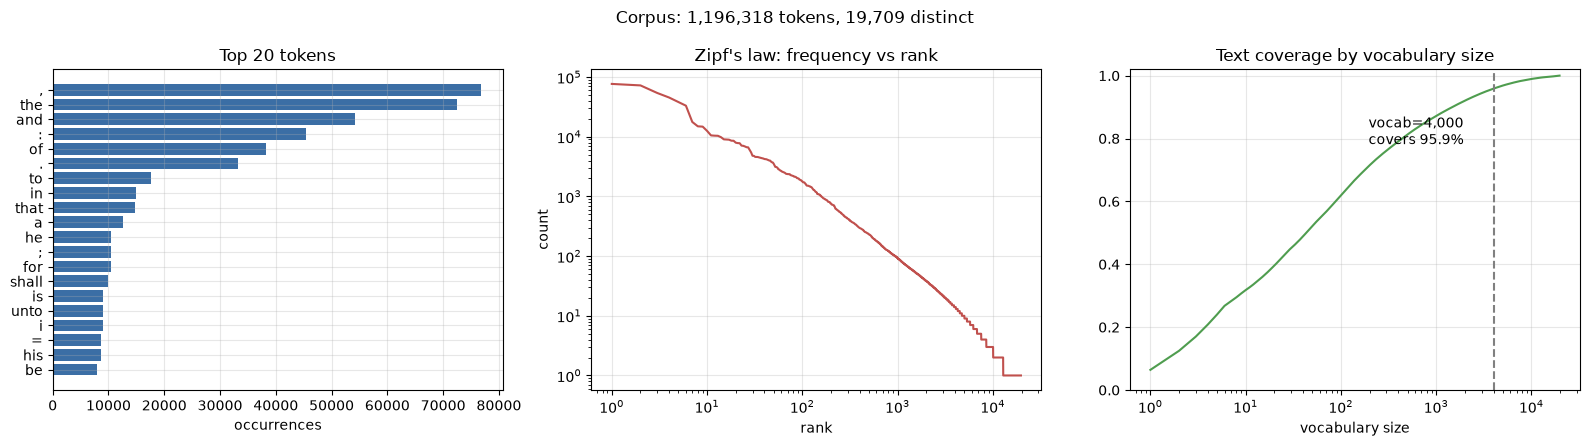

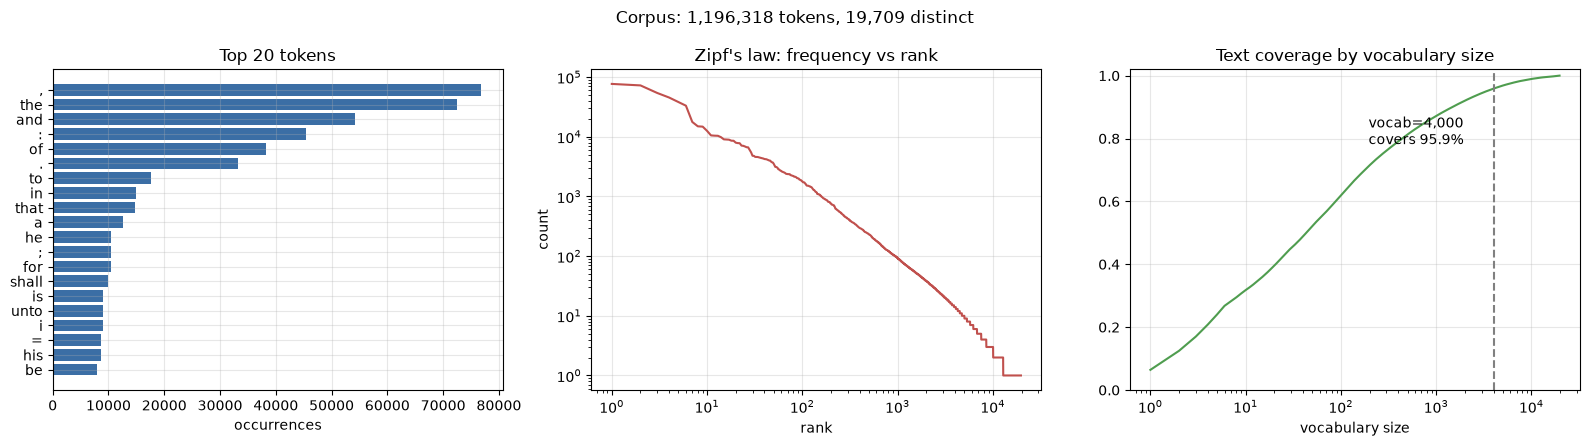

In [6]:
from myllm.plots import corpus_figure
corpus_figure(DATA, vocab_size=4000)

> 💬 **Discussion:** the curve on the right is why we can use a *small* vocabulary:
> the 4,000 most frequent tokens already cover most of the running text.

## 4. Train / validation split

We hide ~5 % of the text from the model and use it only to measure progress. If we scored the model on text
it trained on we could not tell *learning* from *memorising*.

**Why interleaved?** The corpus is Bible first, Bitcoin last. Using "the last 5 %" as validation would test
only Bitcoin text. Instead `split_ids` cuts the token stream into chunks of 256 tokens and gives every 20th chunk to validation,
so validation is spread across the whole corpus.

1,196,318 tokens -> train 1,136,670 | validation 59,648 (5.0%)


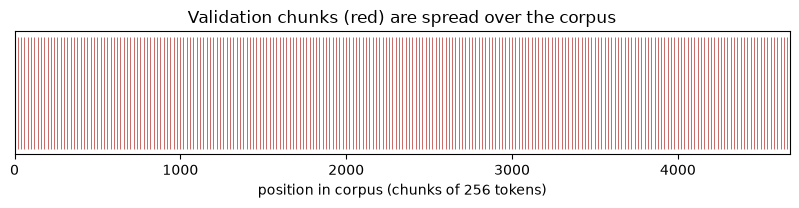

In [7]:
from myllm.tokenizer import WordTokenizer
from myllm.data import split_ids, CHUNK, VAL_EVERY

tok = WordTokenizer.train(corpus, vocab_size=4000)
ids = tok.encode(corpus)
train_ids, val_ids = split_ids(ids)
print(f"{len(ids):,} tokens -> train {len(train_ids):,} | validation {len(val_ids):,} ({len(val_ids)/len(ids):.1%})")

# which chunks went to validation?
n_chunks = len(ids) // CHUNK
is_val = [(n % VAL_EVERY == VAL_EVERY - 1) for n in range(n_chunks)]
fig, ax = plt.subplots(figsize=(10, 1.6))
ax.vlines([i for i, v in enumerate(is_val) if v], 0, 1, color="#c0504d", lw=0.6)
ax.set(xlim=(0, n_chunks), yticks=[], xlabel=f"position in corpus (chunks of {CHUNK} tokens)", title="Validation chunks (red) are spread over the corpus")
ax.grid(False)

## 5. Batches: the heart of next-token training

For every position the model must predict the **next** token. So from a window of text
we build two tensors: the input `x` and the target `y`, where `y` is `x` shifted left by one.

```
text :  the  lord  said  unto  moses
x    :  the  lord  said  unto
y    :       lord  said  unto  moses      ← what the model must predict at each position
```

In [8]:
from myllm.data import get_batch
g = torch.Generator().manual_seed(0)
x, y = get_batch(train_ids, batch_size=2, block_size=12, generator=g)
print("x shape:", tuple(x.shape), "  y shape:", tuple(y.shape))
for i in range(2):
    print()
    print("x:", tok.decode(x[i]))
    print("y:", tok.decode(y[i]))
assert torch.equal(x[:, 1:], y[:, :-1])   # y really is x shifted by one

x shape: (2, 12)   y shape: (2, 12)

x: not to teach and preach jesus christ. 6: 1 and
y: to teach and preach jesus christ. 6: 1 and in

x: lord, and consumed the two hundred and fifty men that offered
y: , and consumed the two hundred and fifty men that offered incense


Each batch is just random windows cut from the token stream, so every window teaches the model
`block_size` predictions at once (one per position).

---
## ✅ Key takeaways

- The corpus is cleaned (license text, URLs removed) before tokenization.
- Validation data is held out and interleaved so it represents the whole corpus.
- A batch is `(x, y)` with `y = x` shifted by one: every position is a training example.

## 🧪 Exercises

1. Print the 30 most common tokens in the *validation* split and compare to the *train* split. Are they similar?
2. Change `VAL_EVERY` to 5. What fraction is validation now? What is the trade-off?
3. Write a cleaning step that removes the markup lines found above (extend `clean_text`). How many tokens disappear?
4. Add your own `.txt` file to `data/raw/` and re-run the lesson. Does Zipf's law still hold?

## ➡️ Next

**Lesson 2 — Tokenization:** how words become the integers the model actually sees.